# Exploración de datos — Resultados Saber 11

**Pregunta de negocio:** ¿Qué estudiantes (y colegios/municipios) tienen mayor riesgo de obtener un puntaje
global bajo en Saber 11, dadas sus características socioeconómicas y del colegio, para priorizar intervenciones
de refuerzo?

**Datos:** datos.gov.co — *Resultados únicos Saber 11* (id `kgxf-xxbe`), periodo `20224`.
Los datos se versionan con DVC (`dvc pull` para obtenerlos; `dvc repro` para regenerarlos).

**Variable de riesgo:** `riesgo_bajo_desempeno = 1` si `punt_global` < percentil 25 nacional.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlecolor": INK, "font.size": 9,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png")

df = pd.read_parquet(ROOT / "data" / "processed" / "saber11_clean.parquet")
SCORES = ["punt_lectura_critica", "punt_matematicas", "punt_c_naturales",
          "punt_sociales_ciudadanas", "punt_ingles", "punt_global"]
P25 = df.loc[df.riesgo_bajo_desempeno == 0, "punt_global"].min()
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]} | Umbral de riesgo (P25): {P25:.0f}")
df.head()

Filas: 532,788 | Columnas: 36 | Umbral de riesgo (P25): 210


,periodo,estu_consecutivo,estu_genero,estu_depto_reside,estu_mcpio_reside,fami_estratovivienda,fami_educacionmadre,fami_educacionpadre,fami_personashogar,fami_cuartoshogar,...,cole_cod_mcpio_ubicacion,punt_lectura_critica,punt_matematicas,punt_c_naturales,punt_sociales_ciudadanas,punt_ingles,punt_global,desemp_ingles,edad,riesgo_bajo_desempeno
0,20224,SB11202240237213,F,CUNDINAMARCA,VILLA DE SAN DIEGO DE UBATÉ,Estrato 3,Educación profesional completa,Educación profesional incompleta,5 a 6,Tres,...,25843,55,53,51,49,49.0,259,A1,17.0,0
1,20224,SB11202240260201,M,NARIÑO,PASTO,Estrato 2,Secundaria (Bachillerato) incompleta,Primaria incompleta,3 a 4,Dos,...,52001,45,57,43,58,53.0,255,A1,18.0,0
2,20224,SB11202240064336,F,NORTE SANTANDER,PAMPLONA,Estrato 2,Secundaria (Bachillerato) completa,Secundaria (Bachillerato) completa,3 a 4,Tres,...,54518,77,62,67,66,75.0,343,B1,17.0,0
3,20224,SB11202240610576,F,GUAVIARE,SAN JOSÉ DEL GUAVIARE,Sin estrato,Primaria incompleta,Secundaria (Bachillerato) incompleta,5 a 6,Tres,...,95025,57,57,44,46,40.0,251,A-,17.0,0
4,20224,SB11202240032963,F,ANTIOQUIA,ITAGÜÍ,Estrato 2,Secundaria (Bachillerato) completa,Técnica o tecnológica completa,3 a 4,Dos,...,05360,52,41,38,33,49.0,208,A1,16.0,1


## 1. Estructura y calidad de los datos

In [2]:
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "% nulos": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(),
}).sort_values("% nulos", ascending=False)
print("Duplicados por estudiante:", df.estu_consecutivo.duplicated().sum())
print("Colegios:", df.cole_cod_dane_establecimiento.nunique(), "| Municipios:", df.cole_cod_mcpio_ubicacion.nunique())
resumen

Duplicados por estudiante: 0
Colegios: 10378 | Municipios: 1114


,tipo,no_nulos,% nulos,valores_unicos
cole_bilingue,str,436722,18.03,2
fami_estratovivienda,str,496878,6.74,7
fami_tieneinternet,str,501136,5.94,2
fami_educacionmadre,str,501781,5.82,12
fami_educacionpadre,str,501888,5.80,12
fami_tieneautomovil,str,508209,4.61,2
fami_cuartoshogar,str,509062,4.45,6
fami_tienelavadora,str,509153,4.44,2
fami_tienecomputador,str,509225,4.42,2
fami_personashogar,str,509908,4.29,5


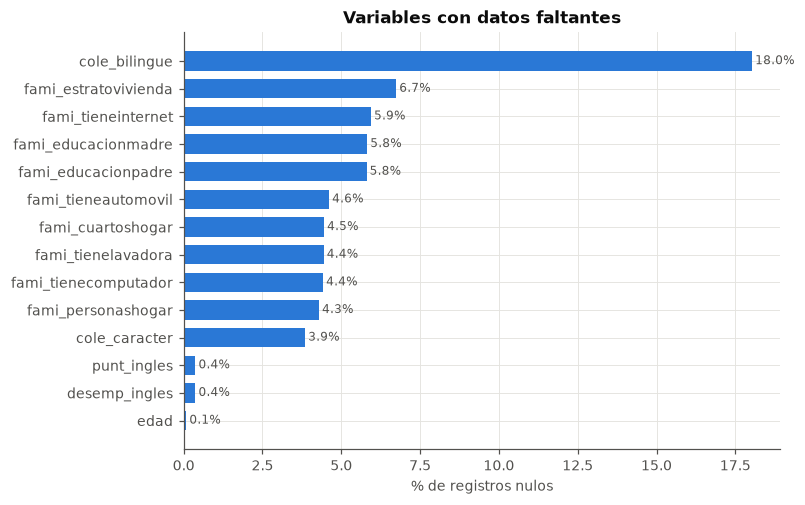

In [3]:
nulos = resumen["% nulos"].loc[lambda s: s > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 0.28 * len(nulos) + 1))
ax.barh(nulos.index, nulos.values, color=BLUE, height=0.7)
ax.set_xlabel("% de registros nulos")
ax.set_title("Variables con datos faltantes")
for y, v in enumerate(nulos.values):
    ax.text(v + 0.1, y, f"{v:.1f}%", va="center", fontsize=8, color=MUTED)
save(fig, "01_nulos")

## 2. Distribución de los puntajes

In [4]:
df[SCORES + ["edad"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
punt_lectura_critica,532788.0,52.8,10.8,0.0,45.0,53.0,61.0,100.0
punt_matematicas,532788.0,50.6,12.2,0.0,42.0,51.0,59.0,100.0
punt_c_naturales,532788.0,49.1,10.4,0.0,41.0,48.0,56.0,100.0
punt_sociales_ciudadanas,532788.0,47.7,11.9,0.0,38.0,47.0,57.0,100.0
punt_ingles,530811.0,49.9,13.1,0.0,39.0,49.0,58.0,100.0
punt_global,532788.0,250.1,51.8,12.0,210.0,247.0,288.0,477.0
edad,532345.0,17.6,2.7,13.0,17.0,17.0,18.0,60.0


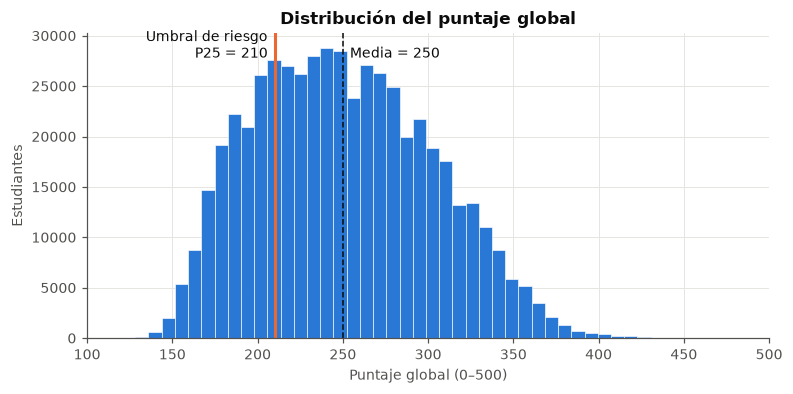

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(df.punt_global, bins=60, color=BLUE, edgecolor="white", linewidth=0.4)
ax.axvline(P25, color=ORANGE, lw=2)
ax.text(P25 - 4, ax.get_ylim()[1] * 0.92, f"Umbral de riesgo\nP25 = {P25:.0f}", ha="right", color=INK, fontsize=9)
ax.axvline(df.punt_global.mean(), color=INK, lw=1, ls="--")
ax.text(df.punt_global.mean() + 4, ax.get_ylim()[1] * 0.92, f"Media = {df.punt_global.mean():.0f}", color=INK, fontsize=9)
ax.set_xlim(100, 500)
ax.set_xlabel("Puntaje global (0–500)"); ax.set_ylabel("Estudiantes")
ax.set_title("Distribución del puntaje global")
save(fig, "02_dist_global")

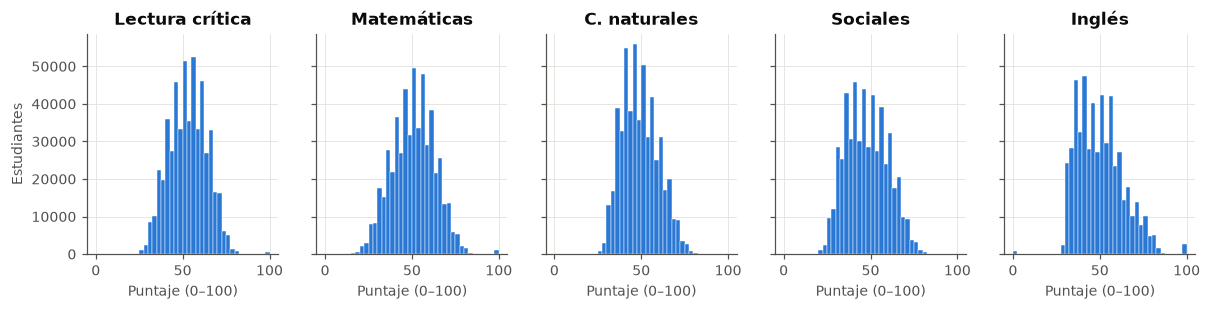

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(13, 2.6), sharey=True)
names = ["Lectura crítica", "Matemáticas", "C. naturales", "Sociales", "Inglés"]
for ax, col, name in zip(axes, SCORES[:-1], names):
    ax.hist(df[col].dropna(), bins=40, color=BLUE, edgecolor="white", linewidth=0.3)
    ax.set_title(name); ax.set_xlabel("Puntaje (0–100)")
axes[0].set_ylabel("Estudiantes")
save(fig, "03_dist_areas")

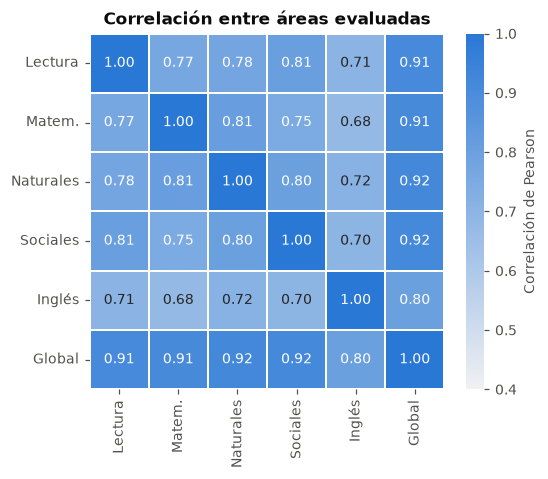

In [7]:
corr = df[SCORES].corr()
labels = ["Lectura", "Matem.", "Naturales", "Sociales", "Inglés", "Global"]
fig, ax = plt.subplots(figsize=(5.2, 4.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.light_palette(BLUE, as_cmap=True), vmin=0.4, vmax=1,
            xticklabels=labels, yticklabels=labels, cbar_kws={"label": "Correlación de Pearson"}, ax=ax,
            linewidths=1, linecolor="white")
ax.set_title("Correlación entre áreas evaluadas")
save(fig, "04_correlacion")

## 3. Brechas socioeconómicas
Para cada factor se compara el puntaje global medio y la **tasa de riesgo** (% de estudiantes bajo el P25).

In [8]:
def perfil(col, order=None, min_n=500):
    g = (df.groupby(col, observed=True)
           .agg(n=("punt_global", "size"), punt_medio=("punt_global", "mean"),
                tasa_riesgo=("riesgo_bajo_desempeno", "mean"))
           .query("n >= @min_n"))
    g["tasa_riesgo"] *= 100
    if order is not None:
        g = g.reindex([o for o in order if o in g.index])
    return g.round(1)

def barras_riesgo(tabla, titulo, nombre, figsize=(7, 3.2)):
    fig, ax = plt.subplots(figsize=figsize)
    y = np.arange(len(tabla))
    ax.barh(y, tabla.tasa_riesgo, color=ORANGE, height=0.65)
    ax.set_yticks(y, tabla.index); ax.invert_yaxis()
    ax.axvline(25, color=INK, lw=1, ls="--")
    ax.text(25.5, len(tabla) - 0.4, "promedio nacional (25%)", fontsize=8, color=MUTED)
    for i, (r, p) in enumerate(zip(tabla.tasa_riesgo, tabla.punt_medio)):
        ax.text(r + 0.6, i, f"{r:.0f}%  ·  media {p:.0f}", va="center", fontsize=8, color=MUTED)
    ax.set_xlim(0, max(tabla.tasa_riesgo) * 1.35)
    ax.set_xlabel("% de estudiantes en riesgo (puntaje global < P25)")
    ax.set_title(titulo)
    save(fig, nombre)
    return tabla

,n,punt_medio,tasa_riesgo
fami_estratovivienda,,,
Sin estrato,19781,212.6,55.1
Estrato 1,146333,242.0,27.8
Estrato 2,180091,253.7,20.6
Estrato 3,110254,263.2,17.9
Estrato 4,28092,267.4,22.8
Estrato 5,8448,261.4,29.3
Estrato 6,3879,245.1,40.8


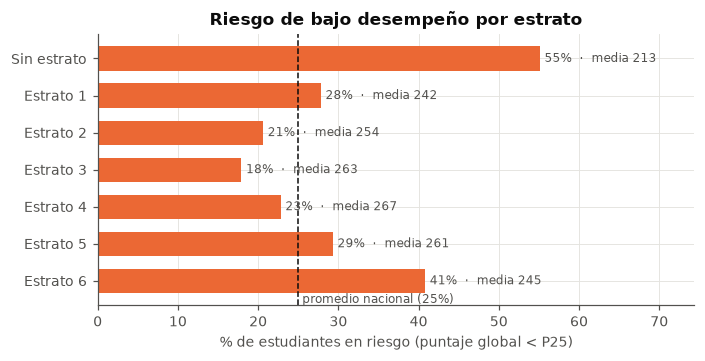

In [9]:
estratos = ["Sin estrato", "Estrato 1", "Estrato 2", "Estrato 3", "Estrato 4", "Estrato 5", "Estrato 6"]
barras_riesgo(perfil("fami_estratovivienda", estratos), "Riesgo de bajo desempeño por estrato", "05_riesgo_estrato")

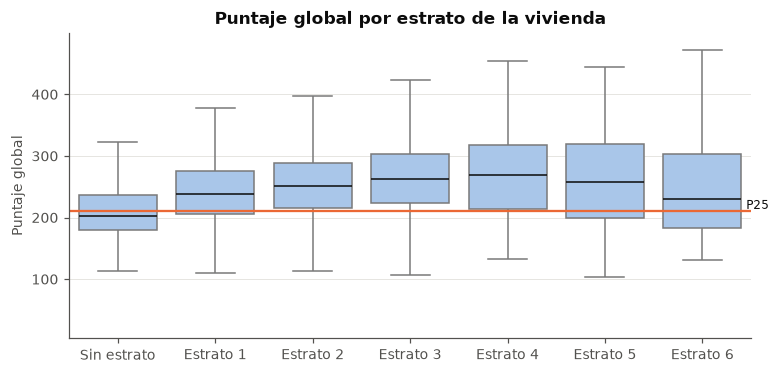

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
d = df[df.fami_estratovivienda.isin(estratos)]
sns.boxplot(data=d, x="fami_estratovivienda", y="punt_global", order=estratos, color="#9ec5f4",
            fliersize=0, linewidth=1, ax=ax, medianprops={"color": INK})
ax.axhline(P25, color=ORANGE, lw=1.5); ax.text(6.45, P25 + 4, "P25", color=INK, fontsize=8)
ax.set_xlabel(""); ax.set_ylabel("Puntaje global"); ax.set_title("Puntaje global por estrato de la vivienda")
save(fig, "06_box_estrato")

,n,punt_medio,tasa_riesgo
fami_educacionmadre,,,
Ninguno,10260,211.2,55.4
Primaria incompleta,62878,228.8,37.3
Primaria completa,42124,233.4,34.5
Secundaria (Bachillerato) incompleta,69872,238.8,29.6
Secundaria (Bachillerato) completa,143736,249.4,23.2
Técnica o tecnológica incompleta,17978,259.9,16.1
Técnica o tecnológica completa,52289,268.0,12.7
Educación profesional incompleta,15218,271.7,13.5
Educación profesional completa,62318,278.4,12.3


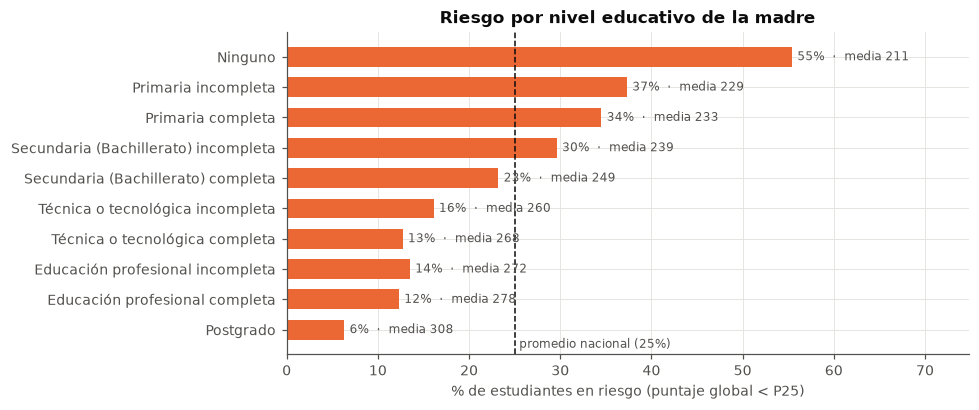

In [11]:
edu_order = ["Ninguno", "Primaria incompleta", "Primaria completa", "Secundaria (Bachillerato) incompleta",
             "Secundaria (Bachillerato) completa", "Técnica o tecnológica incompleta", "Técnica o tecnológica completa",
             "Educación profesional incompleta", "Educación profesional completa", "Postgrado"]
barras_riesgo(perfil("fami_educacionmadre", edu_order), "Riesgo por nivel educativo de la madre", "07_riesgo_edu_madre",
              figsize=(8, 3.8))

,n,punt_medio,tasa_riesgo
Internet: No,137328,228.4,38.7
Internet: Si,363808,260.2,18.5
Computador: No,237559,233.8,34.0
Computador: Si,271666,265.5,16.2
Automóvil: No,379398,244.8,26.9
Automóvil: Si,128811,268.4,17.1
Lavadora: No,114946,234.6,34.6
Lavadora: Si,394207,255.4,21.6


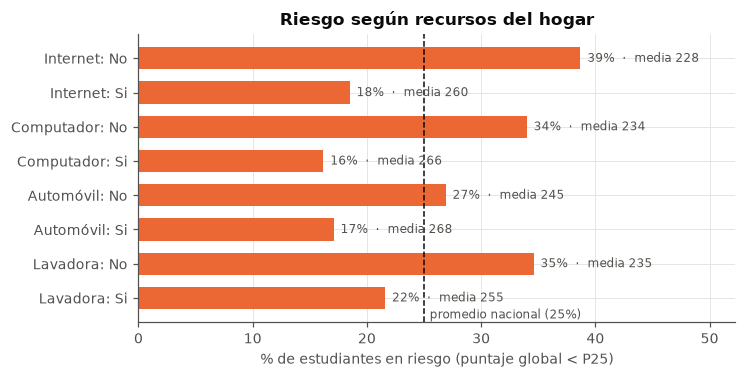

In [12]:
recursos = []
for col, nombre in [("fami_tieneinternet", "Internet"), ("fami_tienecomputador", "Computador"),
                    ("fami_tieneautomovil", "Automóvil"), ("fami_tienelavadora", "Lavadora")]:
    t = perfil(col).rename(index=lambda v: f"{nombre}: {v}")
    recursos.append(t)
barras_riesgo(pd.concat(recursos), "Riesgo según recursos del hogar", "08_riesgo_recursos", figsize=(7, 3.4))

## 4. Características del colegio

,n,punt_medio,tasa_riesgo
Naturaleza: NO OFICIAL,120477,272.6,16.3
Naturaleza: OFICIAL,412310,243.6,27.5
Zona: RURAL,91213,228.4,40.3
Zona: URBANO,441574,254.6,21.8
Bilingüe: N,431065,252.1,23.5
Bilingüe: S,5657,247.0,31.1
Calendario: A,530561,250.2,24.9
Calendario: B,682,263.3,25.4
Calendario: OTRO,1544,237.0,32.2


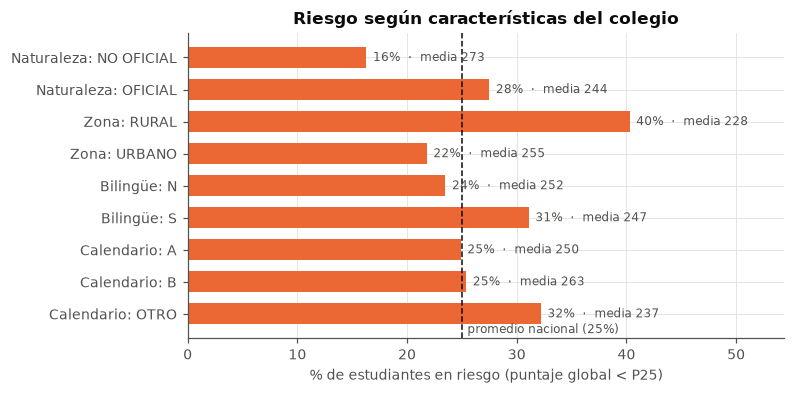

In [13]:
colegio = []
for col, nombre in [("cole_naturaleza", "Naturaleza"), ("cole_area_ubicacion", "Zona"),
                    ("cole_bilingue", "Bilingüe"), ("cole_calendario", "Calendario")]:
    colegio.append(perfil(col).rename(index=lambda v: f"{nombre}: {v}"))
barras_riesgo(pd.concat(colegio), "Riesgo según características del colegio", "09_riesgo_colegio", figsize=(7, 3.6))

,n,punt_medio,tasa_riesgo
cole_jornada,,,
COMPLETA,76896,280.8,11.7
UNICA,146358,252.0,21.0
MAÑANA,208529,248.2,25.4
TARDE,49187,245.5,25.5
SABATINA,28116,212.7,52.7
NOCHE,23701,210.6,54.6


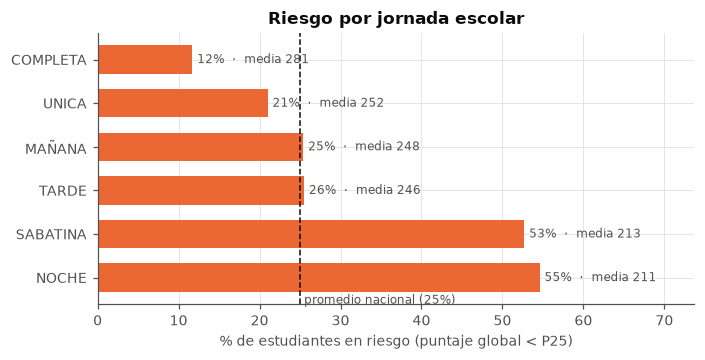

In [14]:
barras_riesgo(perfil("cole_jornada").sort_values("tasa_riesgo"), "Riesgo por jornada escolar", "10_riesgo_jornada")

cole_naturaleza,NO OFICIAL,OFICIAL
fami_estratovivienda,,
Sin estrato,45.5,56.2
Estrato 1,28.8,27.7
Estrato 2,17.0,21.5
Estrato 3,10.6,22.1
Estrato 4,7.5,40.1
Estrato 5,9.5,52.9
Estrato 6,12.3,63.8


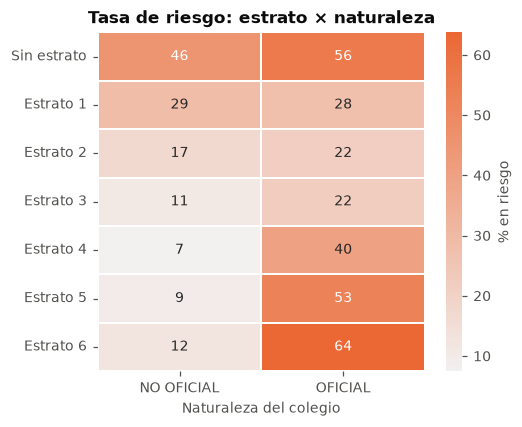

In [15]:
piv = (df[df.fami_estratovivienda.isin(estratos)]
       .pivot_table(index="fami_estratovivienda", columns="cole_naturaleza", values="riesgo_bajo_desempeno",
                    aggfunc="mean").reindex(estratos) * 100)
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(piv, annot=True, fmt=".0f", cmap=sns.light_palette(ORANGE, as_cmap=True), linewidths=1, linecolor="white",
            cbar_kws={"label": "% en riesgo"}, ax=ax)
ax.set_xlabel("Naturaleza del colegio"); ax.set_ylabel("")
ax.set_title("Tasa de riesgo: estrato × naturaleza")
save(fig, "11_heat_estrato_naturaleza")
piv.round(1)

**Anomalía:** en colegios oficiales la tasa de riesgo *sube* en estratos 4–6. Se verifica si lo explica la
jornada nocturna/sabatina (población adulta).

In [16]:
of = df[(df.cole_naturaleza == "OFICIAL") & ~df.cole_jornada.isin(["SABATINA", "NOCHE"])]
(of.groupby("fami_estratovivienda").riesgo_bajo_desempeno.mean().reindex(estratos) * 100).round(1)

fami_estratovivienda
Sin estrato    53.9
Estrato 1      25.2
Estrato 2      19.5
Estrato 3      20.1
Estrato 4      37.6
Estrato 5      50.6
Estrato 6      61.4
Name: riesgo_bajo_desempeno, dtype: float64

La anomalía persiste sin jornadas de adultos y la edad mediana es igual entre estratos, lo que sugiere
**errores de autorreporte del estrato** en colegios oficiales. Para el modelo, el estrato debe usarse junto con
variables más confiables (educación de los padres, internet, computador) y no de forma aislada.

## 5. Dimensión geográfica

,n,punt_medio,tasa_riesgo
cole_depto_ubicacion,,,
CHOCO,4818,206.1,61.0
VAUPES,434,213.7,53.9
AMAZONAS,823,215.5,51.4
VICHADA,609,217.9,47.8
LA GUAJIRA,9775,221.5,46.8
GUAINIA,389,224.2,46.8
MAGDALENA,16865,227.5,41.6
BOLIVAR,27212,230.0,41.3
CAUCA,13722,231.1,38.0


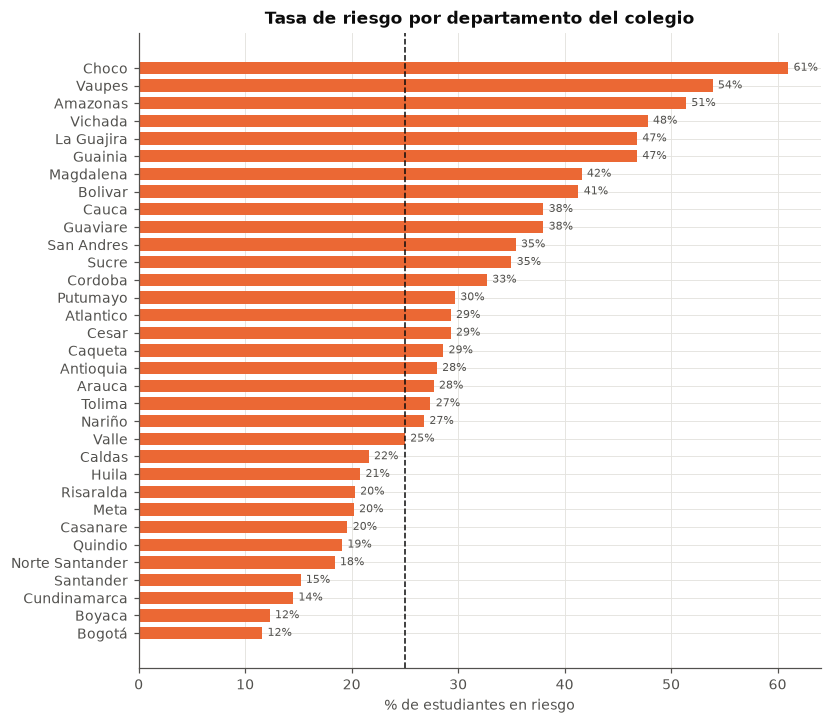

In [17]:
dep = perfil("cole_depto_ubicacion", min_n=200).sort_values("tasa_riesgo", ascending=False)
fig, ax = plt.subplots(figsize=(8, 7.5))
y = np.arange(len(dep))
ax.barh(y, dep.tasa_riesgo, color=ORANGE, height=0.7)
ax.set_yticks(y, dep.index.str.title()); ax.invert_yaxis()
ax.axvline(25, color=INK, lw=1, ls="--")
for i, r in enumerate(dep.tasa_riesgo):
    ax.text(r + 0.5, i, f"{r:.0f}%", va="center", fontsize=7, color=MUTED)
ax.set_xlabel("% de estudiantes en riesgo"); ax.set_title("Tasa de riesgo por departamento del colegio")
save(fig, "12_riesgo_depto")
dep

In [18]:
mun = (df.groupby(["cole_depto_ubicacion", "cole_mcpio_ubicacion"])
         .agg(n=("punt_global", "size"), punt_medio=("punt_global", "mean"),
              tasa_riesgo=("riesgo_bajo_desempeno", "mean")).query("n >= 100"))
mun["tasa_riesgo"] *= 100
print(f"Municipios con ≥100 evaluados: {len(mun)}")
print("Municipios con tasa de riesgo ≥ 50%:", (mun.tasa_riesgo >= 50).sum())
mun.sort_values("tasa_riesgo", ascending=False).head(15).round(1)

Municipios con ≥100 evaluados: 659
Municipios con tasa de riesgo ≥ 50%: 115


n  punt_medio  tasa_riesgo
cole_depto_ubicacion cole_mcpio_ubicacion                                 
CHOCO                BOJAYÁ                   120       170.3         97.5
                     EL LITORAL DEL SAN JUAN  125       172.2         96.8
CAUCA                LÓPEZ DE MICAY           114       179.3         90.4
                     TIMBIQUÍ                 194       180.9         86.1
CHOCO                ALTO BAUDÓ               116       176.3         84.5
NARIÑO               EL CHARCO                246       191.4         78.9
CHOCO                MEDIO SAN JUAN           106       189.1         77.4
ANTIOQUIA            ANORÍ                    447       192.3         76.7
MAGDALENA            PUEBLOVIEJO              253       193.7         76.3
CHOCO                BAJO BAUDÓ               130       191.8         76.2
LA GUAJIRA           MANAURE                  666       188.0         76.1
RISARALDA            PUEBLO RICO              137       191.9         75.9
ANTIOQUIA            VIGÍA DEL FUERTE         124       190.6         75.0
CHOCO                RIOSUCIO                 259       191.8         74.1
CAUCA                GUAPÍ                    325       194.0         73.5

Colegios con ≥50% de estudiantes en riesgo: 1172


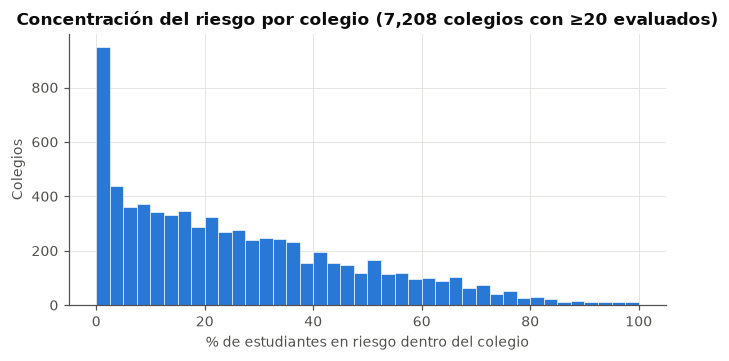

In [19]:
cole = (df.groupby("cole_cod_dane_establecimiento")
          .agg(n=("punt_global", "size"), tasa_riesgo=("riesgo_bajo_desempeno", "mean")).query("n >= 20"))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(cole.tasa_riesgo * 100, bins=40, color=BLUE, edgecolor="white", linewidth=0.4)
ax.set_xlabel("% de estudiantes en riesgo dentro del colegio"); ax.set_ylabel("Colegios")
ax.set_title(f"Concentración del riesgo por colegio ({len(cole):,} colegios con ≥20 evaluados)")
save(fig, "13_riesgo_colegios")
print("Colegios con ≥50% de estudiantes en riesgo:", (cole.tasa_riesgo >= 0.5).sum())

## 6. Poder explicativo de las variables candidatas
Se calcula η² (proporción de la varianza del puntaje global explicada por cada variable categórica)
como una primera guía de selección de variables para el modelo.

fami_educacionmadre     0.133
fami_educacionpadre     0.112
cole_jornada            0.105
fami_tienecomputador    0.094
fami_tieneinternet      0.075
cole_depto_ubicacion    0.074
cole_naturaleza         0.055
fami_estratovivienda    0.051
fami_tieneautomovil     0.039
cole_area_ubicacion     0.036
fami_tienelavadora      0.028
fami_personashogar      0.024
cole_genero             0.016
fami_cuartoshogar       0.013
cole_caracter           0.006
estu_genero             0.005
cole_calendario         0.000
cole_bilingue           0.000
dtype: float64

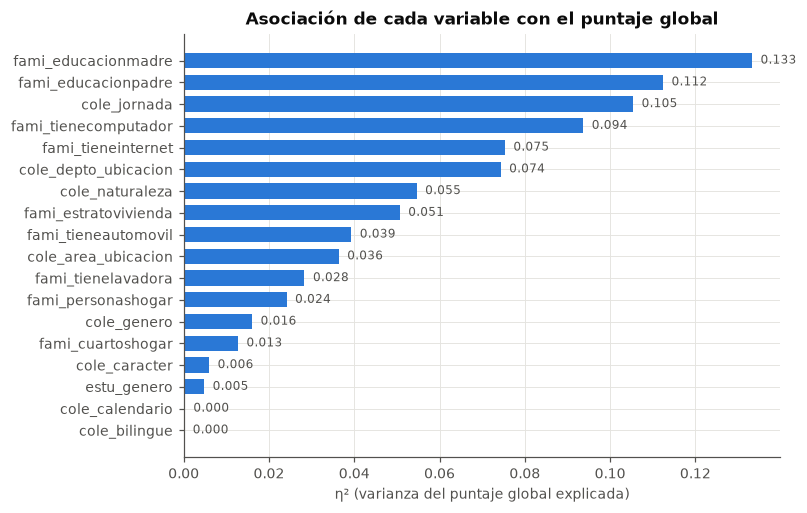

In [20]:
def eta2(col):
    d = df[[col, "punt_global"]].dropna()
    m = d.punt_global.mean()
    g = d.groupby(col).punt_global.agg(["mean", "size"])
    return ((g["mean"] - m) ** 2 * g["size"]).sum() / ((d.punt_global - m) ** 2).sum()

cands = ["fami_estratovivienda", "fami_educacionmadre", "fami_educacionpadre", "fami_tieneinternet",
         "fami_tienecomputador", "fami_tieneautomovil", "fami_tienelavadora", "fami_personashogar",
         "fami_cuartoshogar", "estu_genero", "cole_naturaleza", "cole_area_ubicacion", "cole_jornada",
         "cole_bilingue", "cole_calendario", "cole_caracter", "cole_genero", "cole_depto_ubicacion"]
imp = pd.Series({c: eta2(c) for c in cands}).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values, color=BLUE, height=0.7)
for i, v in enumerate(imp.values):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8, color=MUTED)
ax.set_xlabel("η² (varianza del puntaje global explicada)"); ax.set_title("Asociación de cada variable con el puntaje global")
save(fig, "14_eta2")
imp.sort_values(ascending=False).round(3)

In [21]:
print("Balance de la variable objetivo:")
print(df.riesgo_bajo_desempeno.value_counts(normalize=True).round(3))

Balance de la variable objetivo:
riesgo_bajo_desempeno
0    0.75
1    0.25
Name: proportion, dtype: float64


## 7. Conclusiones para el modelo y el tablero
1. **Calidad:** la fuente publica cada registro dos veces (1.07 M → 532.788 estudiantes únicos); hay 4 pruebas
   anuladas (puntaje 0). Las variables socioeconómicas tienen 4–7 % de nulos y `cole_bilingue` 18 %: se imputará
   una categoría "Sin información" en lugar de eliminar filas.
2. **Objetivo:** el puntaje global (media 250, DE 52) es aproximadamente normal; el umbral de riesgo P25 = 210 deja
   una clase positiva del 25 %, moderadamente desbalanceada (usar AUC/recall y ponderación de clases).
3. **Factores del hogar:** la educación de la madre es la variable con mayor asociación (η² = 0,13): el riesgo pasa
   de 55 % (sin educación) a 6 % (posgrado). No tener internet o computador duplica el riesgo (≈ 35–39 % vs 16–19 %).
4. **Factores del colegio:** jornada nocturna/sabatina (≈ 53–55 % de riesgo), zona rural (40 %) y colegio oficial
   (28 % vs 16 %) concentran el riesgo.
5. **Territorio:** brechas muy grandes entre departamentos (Chocó 61 % vs Bogotá 12 %); 115 municipios y 1.172
   colegios tienen ≥ 50 % de estudiantes en riesgo → el tablero debe permitir focalizar a nivel municipio/colegio.
6. **Estrato:** relación no monótona por posibles errores de autorreporte en colegios oficiales; no usarlo aislado.
7. **Áreas:** los puntajes por área están muy correlacionados entre sí (0,68–0,81), por lo que **no** se usarán como
   predictores (serían fuga de información); el modelo usará solo variables disponibles antes de la prueba.